# Show Evaluation 2 Results
Shows the present results of eval 2.

## 1. Setup

In [1]:
import os

from foodrag.persona import qa_generator
from foodrag.utils import load_util
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from foodrag.utils import analysis_util

# Set working directory
os.chdir("....")  # Change to the root directory of the project
cwd = os.getcwd()
print("Current Working Directory:", cwd)

Current Working Directory: D:\DataspellProjects\foodRAG


In [2]:
## Output Paths
data_path = './data'
qa_name = 'big_1'
run_name = 'eval_2_2'
load_util.ensure_dir(data_path + "/runs/" + run_name)

In [3]:
# Load the current recipes data
hummus = load_util.get_current_hummus(data_path + "/full_hummus")
recipes_df = hummus['recipes_df']

In [6]:
# Explore the dataset
display(recipes_df[recipes_df['title'] == 'Farfalle With Broccoli and Sausage'])


,recipe_id,title,description,author_id,duration,directions,ingredients,serves,last_changed_date,food_kg_locator,...,sugars [g],protein [g],who_score,fsa_score,nutri_score,normalization_comment,direction_size,ingredients_sizes,ingredient_names,meal_types
296,296,Farfalle With Broccoli and Sausage,"This dish is so fresh and delicious tasting, m...",27558,30.0,"[Over medium heat, brown sausage, breaking up ...","{'': [('hot Italian sausage', '1 time(s) lb '...",6,2009-01-16,http://idea.rpi.edu/heals/kb/recipe/b1ffd79a-F...,...,2.4,26.1,0.206816,0.25,0.0,NaN,4,7,"[farfalle pasta, frozen broccoli, garlic clove...","[lunch, dinner]"


In [ ]:
# Decrease necessary RAM by removing not used columns
del hummus

## 2. Analysis full QA set

In [ ]:
# Load question-answer pairs & their embeddings (only the recipe qa's)
question_answer_sets = qa_generator.load_qa_set(data_path, sub_dir_name=qa_name, recipes_df=recipes_df, disable_meal_plan_set=True)['recipe_question_answer_set']

In [5]:
# Average number of valid answers per question
answer_df, requirement_df, nutri_df, fsa_df  = analysis_util.compute_answer_stats_df(question_answer_sets)
print("Answers stats:")
display(answer_df.T)
print("Requirements stats:")
display(requirement_df.T)
print("NutriScore stats:")
display(nutri_df.T)
print("FSA score stats:")
display(fsa_df.T)

Answers stats:


,0
mean,12477.359
variance,1619946038.165
std_dev,40248.553
min,0
max,270284
median,0.000
num_questions,9986
percentile_5,
percentile_10,
percentile_15,


Requirements stats:


,0
mean,5.018
variance,2.261
std_dev,1.504
min,1
max,9
median,5.000
num_questions,9986
percentile_5,
percentile_10,
percentile_15,


NutriScore stats:


,0
mean,0.336
variance,0.061
std_dev,0.246
min,0.000
max,0.750
median,0.287
num_questions,9986
percentile_5,
percentile_10,
percentile_15,


FSA score stats:


,0
mean,0.717
variance,0.040
std_dev,0.201
min,0.000
max,1.000
median,0.750
num_questions,9986
percentile_5,
percentile_10,
percentile_15,


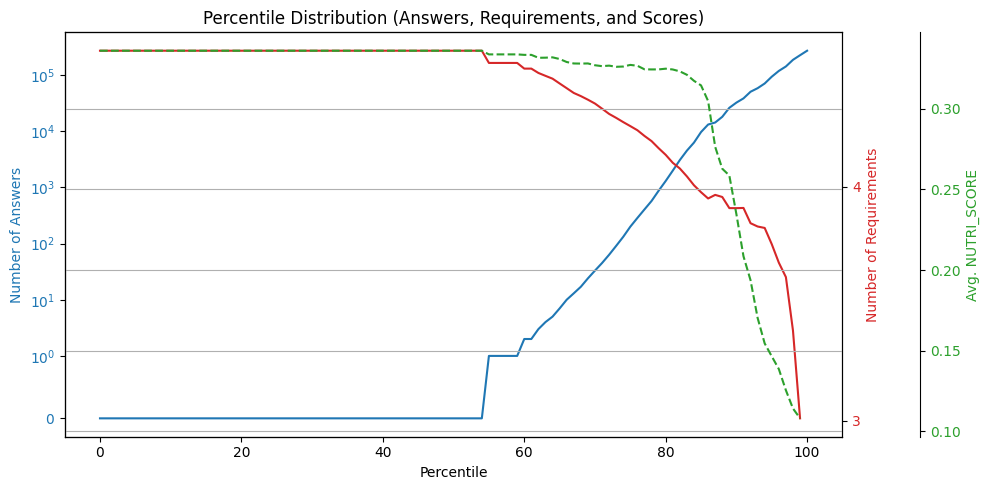

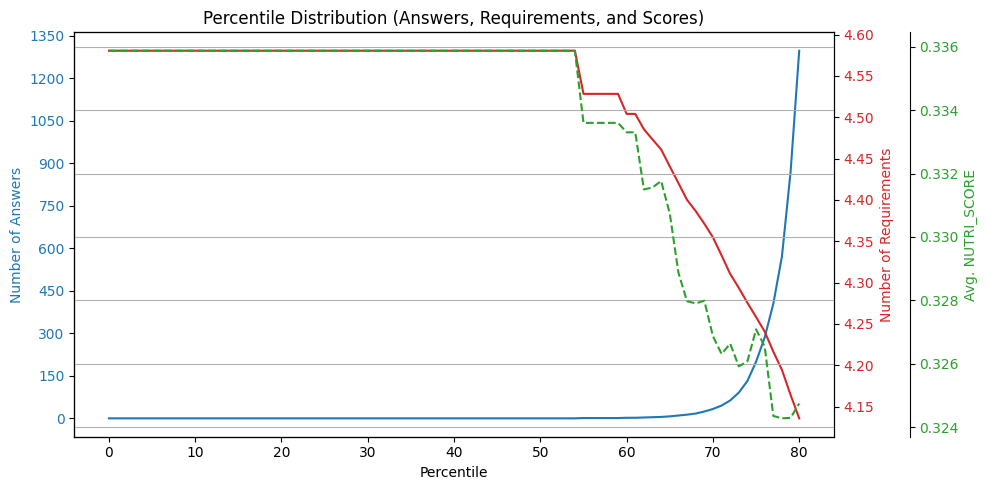

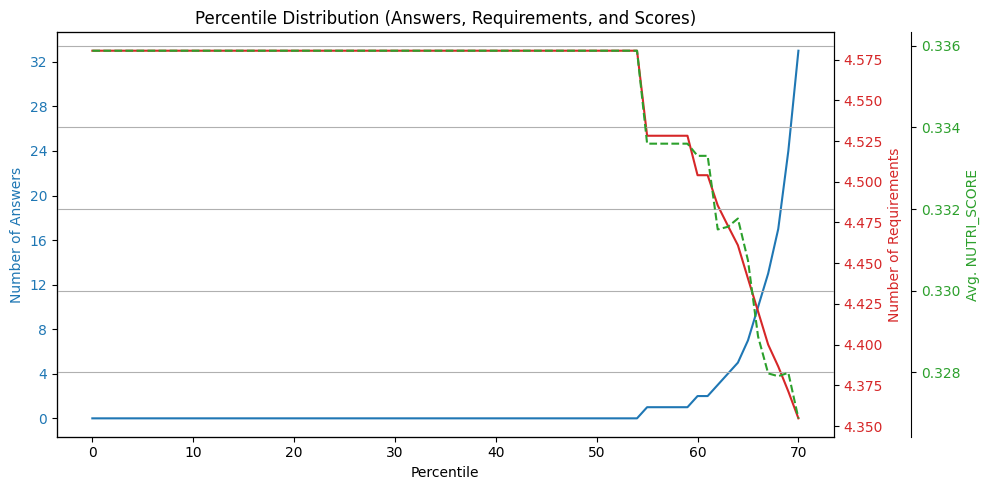

In [6]:
# Plot fine-grained percentiles of answer counts
analysis_util.plot_fine_percentiles(question_answer_sets, plot_requirements=True, score_type='nutri_score', log_y=True, log_y_base=10)
analysis_util.plot_fine_percentiles(question_answer_sets, plot_requirements=True, score_type='nutri_score', upper_bound=80)
analysis_util.plot_fine_percentiles(question_answer_sets, plot_requirements=True, score_type='nutri_score', upper_bound=70)

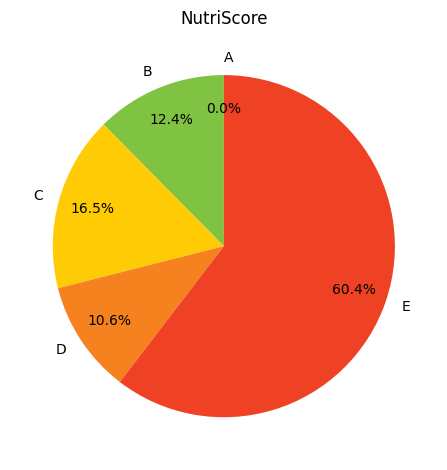

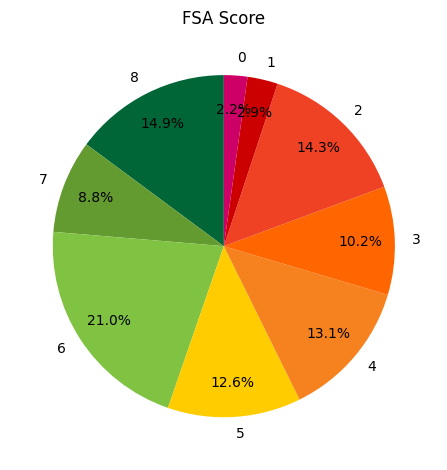

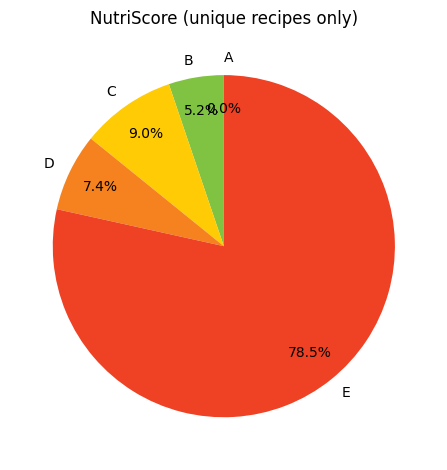

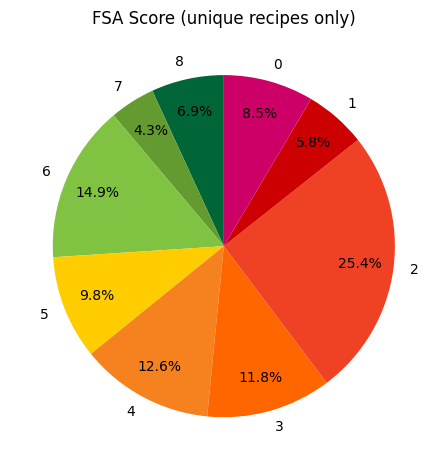

In [7]:
# Merge all answer DataFrames and remove non-necessary columns
merged_recipes_df = [
    entry['answer'][['recipe_id', 'nutri_score', 'fsa_score']]
    for entry in question_answer_sets
]

# Plot nutrition score visualizations with duplicates
analysis_util.plot_food_score_visualizations(merged_recipes_df, drop_duplicates=False)

# Plot nutrition score visualizations without duplicates
analysis_util.plot_food_score_visualizations(merged_recipes_df, drop_duplicates=True)

# 3. Analysis of the non-empty QA set

In [4]:
# Free up memory
try:
    del question_answer_sets
except Exception:
    pass

# Load question-answer pairs & their embeddings (only the recipe qa's)
question_answer_sets = qa_generator.load_qa_set(data_path, sub_dir_name=qa_name, recipes_df=recipes_df, discard_empty_qas=True, disable_meal_plan_set=True)['recipe_question_answer_set']

Loading full recipes for question-answer set(s).
Meal plan question-answer set is disabled. Removing Meal plan question-answer set.
Discarding empty questions in recipe question-answer set.
Removed 0 empty questions in recipe question-answer set.
Removing duplicate questions in recipe question-answer set.
Removed 11 duplicate questions.
Total recipe questions: 4555
Total unique recipes in recipe question-answer set: 270284


In [5]:
# Average number of valid answers per question
answer_df, requirement_df, nutri_df, fsa_df  = analysis_util.compute_answer_stats_df(question_answer_sets)
print("Answers stats:")
display(answer_df.T)
print("Requirements stats:")
display(requirement_df.T)
print("NutriScore stats:")
display(nutri_df.T)
print("FSA score stats:")
display(fsa_df.T)

Answers stats:


,0
mean,27354.315
variance,3144819654.057
std_dev,56078.692
min,1
max,270284
median,431.000
num_questions,4555
percentile_5,
percentile_10,1.000
percentile_15,2.707


Requirements stats:


,0
mean,4.580
variance,2.020
std_dev,1.421
min,1
max,9
median,5.000
num_questions,4555
percentile_5,
percentile_10,5.021
percentile_15,5.017


NutriScore stats:


,0
mean,0.336
variance,0.061
std_dev,0.246
min,0.000
max,0.750
median,0.287
num_questions,4555
percentile_5,
percentile_10,0.355
percentile_15,0.352


FSA score stats:


,0
mean,0.717
variance,0.040
std_dev,0.201
min,0.000
max,1.000
median,0.750
num_questions,4555
percentile_5,
percentile_10,0.740
percentile_15,0.741


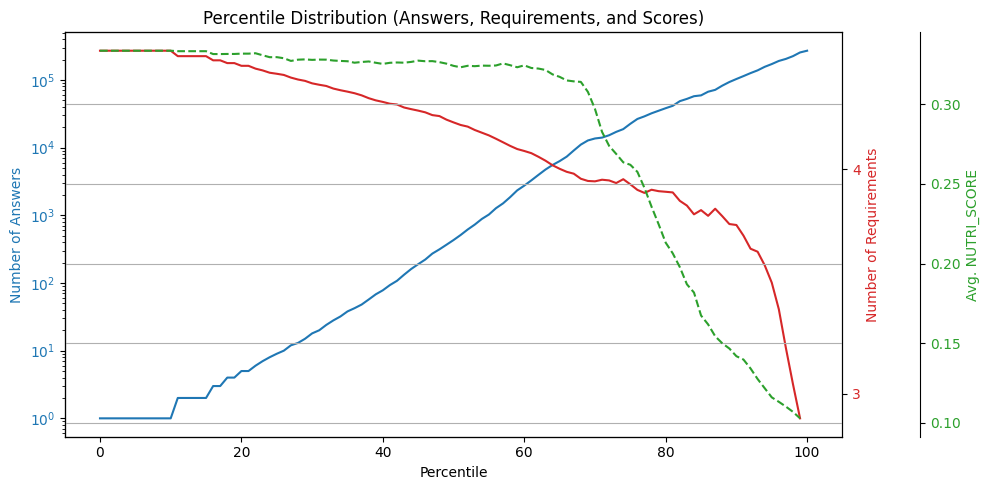

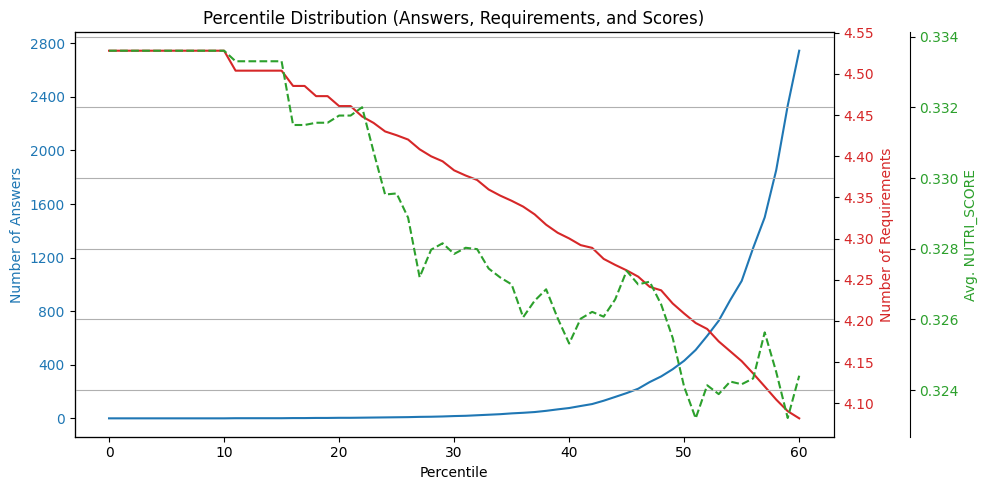

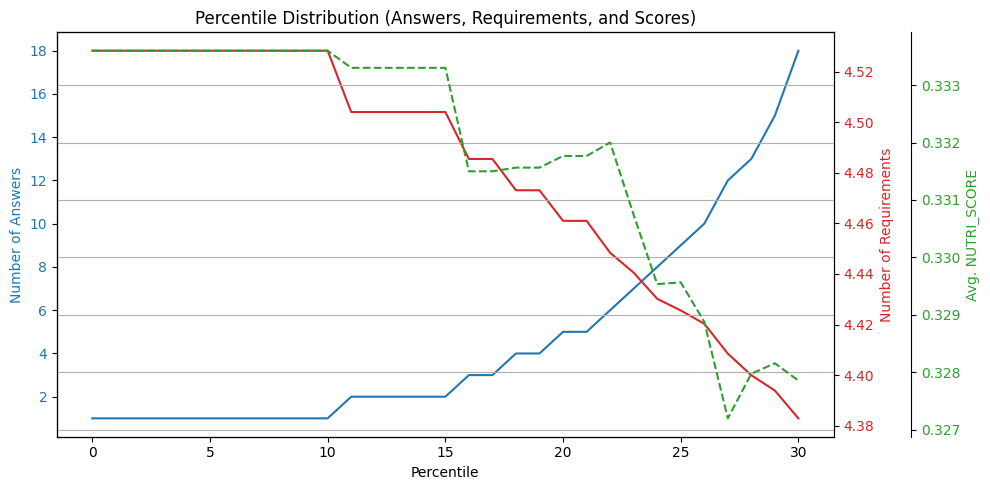

In [6]:
# Plot fine-grained percentiles of answer counts
analysis_util.plot_fine_percentiles(question_answer_sets, plot_requirements=True, score_type='nutri_score', log_y=True, log_y_base=10)
analysis_util.plot_fine_percentiles(question_answer_sets, plot_requirements=True, score_type='nutri_score', upper_bound=60)
analysis_util.plot_fine_percentiles(question_answer_sets, plot_requirements=True, score_type='nutri_score', upper_bound=30)

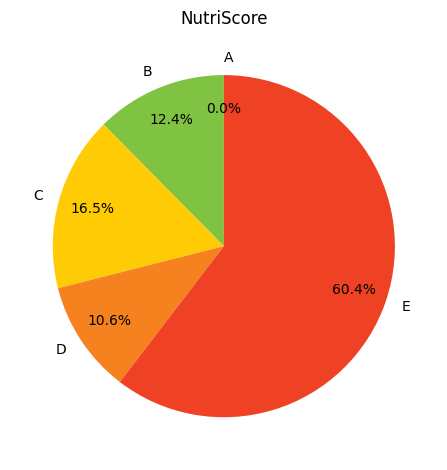

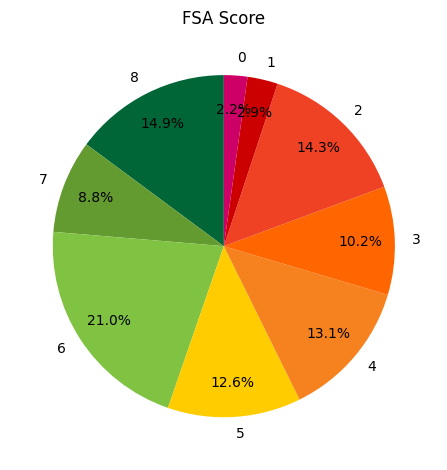

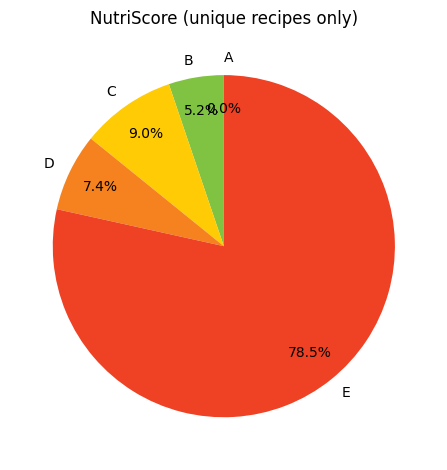

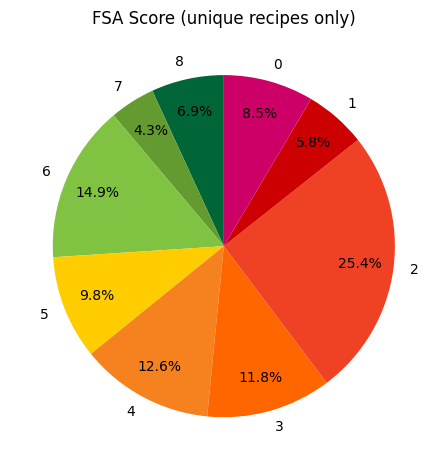

In [7]:
# Merge all answer DataFrames and remove non-necessary columns
merged_recipes_df = [
    entry['answer'][['recipe_id', 'nutri_score', 'fsa_score']]
    for entry in question_answer_sets
]

# Plot nutrition score visualizations with duplicates
analysis_util.plot_food_score_visualizations(merged_recipes_df, drop_duplicates=False)

# Plot nutrition score visualizations without duplicates
analysis_util.plot_food_score_visualizations(merged_recipes_df, drop_duplicates=True)